In [8]:
# ACTIVIDAD 2
# Gráficos y funciones en R
# Lobo marino de Galápagos (Zalophus wollebaeki)

lobos <- read.csv("census_avg.csv")
head(lobos)
head(lobos[, c("SeasonOfRound_extra",
               "Total_avg_ex",
               "Juveniles_avg_ex")])

,SeasonOfRound,Males_avg,Females_avg,Females_max,Adults_avg,All_Adults_avg,Juveniles_avg,Pups_avg,Total_avg,Total_avg_wo_pups,⋯,Males_avg_ex,Females_avg_ex,Adults_avg_ex,All_Adults_avg_ex,Juveniles_avg_ex,Pups_avg_ex,Total_avg_ex,n_counts_ex,Total_avg_wo_pups_ex,Total_avg_wo_fem_pups_ex
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,21,75,93,5,101,88,48,237,189,⋯,21,75,5,101,88,48,237,25,189,114
2,2,32,86,98,4,122,92,86,300,214,⋯,32,86,4,122,92,86,300,12,214,129
3,3,25,64,86,6,95,6,41,142,101,⋯,25,64,6,95,6,41,142,15,101,37
4,4,35,67,93,38,140,91,98,329,231,⋯,34,89,8,131,107,97,335,23,238,149
5,4,35,67,93,38,140,91,98,329,231,⋯,36,61,46,142,87,98,328,8,230,168
6,5,31,81,116,11,122,11,46,179,132,⋯,30,82,8,120,8,41,169,37,129,47


,SeasonOfRound_extra,Total_avg_ex,Juveniles_avg_ex
,<dbl>,<int>,<int>
1,0.5,237,88
2,1.5,300,92
3,2.5,142,6
4,3.5,335,107
5,4.0,328,87
6,4.5,169,8


In [9]:
# Función para calcular una media aritmética
Media <- function(x) {
  x <- x[!is.na(x)]
  resultado <- sum(x) / length(x)

  return(resultado)
}

Media(lobos$Total_avg_ex)
Media(lobos$Juveniles_avg_ex)
Media(lobos$Pups_avg_ex)

[1] 134.7568

[1] 15.24324

[1] 43.08108

In [17]:
grafico_censo <- function(datos, variable, titulo, color) {
  datos <- datos[order(datos$SeasonOfRound_YearStart,
                       datos$SeasonOfRound_extra), ]
  anio <- datos$SeasonOfRound_YearStart
  abundancia <- datos[[variable]]
  plot(
    anio,
    abundancia,
    type = "p",
    col = color,
    pch = 19,
    lwd = 2,
    xaxt = "n",
    xlab = "Año de inicio de la temporada reproductiva",
    ylab = "Promedio de individuos observados",
    main = titulo
  )
  axis(1, at = seq(2003, 2023, by = 2))
  grid()
}

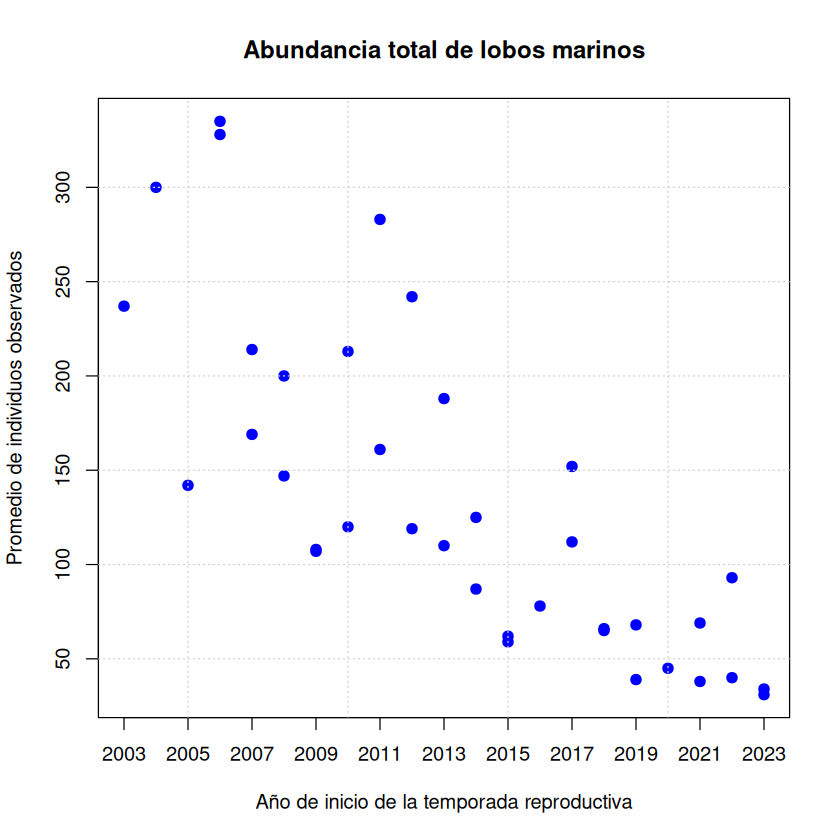

In [18]:
grafico_censo(
  lobos,
  "Total_avg_ex",
  "Abundancia total de lobos marinos",
  "blue"
)

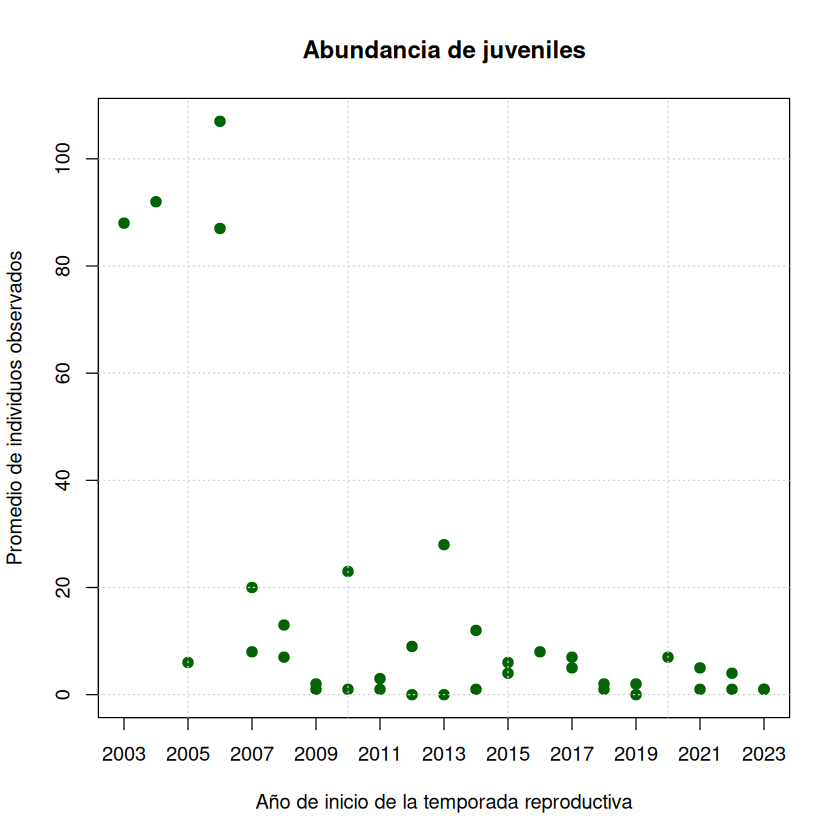

In [19]:
grafico_censo(
  lobos,
  "Juveniles_avg_ex",
  "Abundancia de juveniles",
  "darkgreen"
)

In [20]:
anuales <- lobos[!duplicated(lobos$SeasonOfRound), ]
anuales <- anuales[, c(
  "SeasonOfRound_YearStart",
  "Total_avg",
  "Juveniles_avg"
)]

anuales <- anuales[
  order(anuales$SeasonOfRound_YearStart),
]
print(anuales)

   SeasonOfRound_YearStart Total_avg Juveniles_avg
1                     2003       237            88
2                     2004       300            92
3                     2005       142             6
4                     2006       329            91
6                     2007       179            11
8                     2008       158             8
10                    2009       108             2
12                    2010       140             6
14                    2011       193             1
16                    2012       154             3
18                    2013       120             4
20                    2014        99             4
22                    2015        61             5
24                    2016        78             8
25                    2017       120             5
27                    2018        66             1
29                    2019        44             0
31                    2020        45             7
32                    2021     

In [21]:
grafico_tendencia <- function(datos, variable, titulo, color) {
  anio <- datos$SeasonOfRound_YearStart
  abundancia <- datos[[variable]]
  validos <- !is.na(anio) & !is.na(abundancia)
  anio <- anio[validos]
  abundancia <- abundancia[validos]
  plot(
    anio,
    abundancia,
    type = "b",
    col = color,
    pch = 19,
    lwd = 2,
    xlab = "Año de inicio de la temporada reproductiva",
    ylab = "Promedio de individuos observados",
    main = titulo,
    xaxt = "n"
  )
  axis(1, at = seq(2003, 2023, by = 2))
  grid()
  modelo <- lm(abundancia ~ anio)

  abline(modelo, col = "red", lwd = 2, lty = 2)
  legend(
    "topright",
    legend = c("Promedio anual", "Tendencia lineal"),
    col = c(color, "red"),
    lty = c(1, 2),
    pch = c(19, NA),
    bty = "n",
    cex = 0.8
  )
  pendiente <- coef(modelo)[2]

  cat("Cambio lineal estimado:",
      round(pendiente, 2),
      "individuos por año\n")
  return(invisible(modelo))
}

Cambio lineal estimado: -11.42 individuos por año


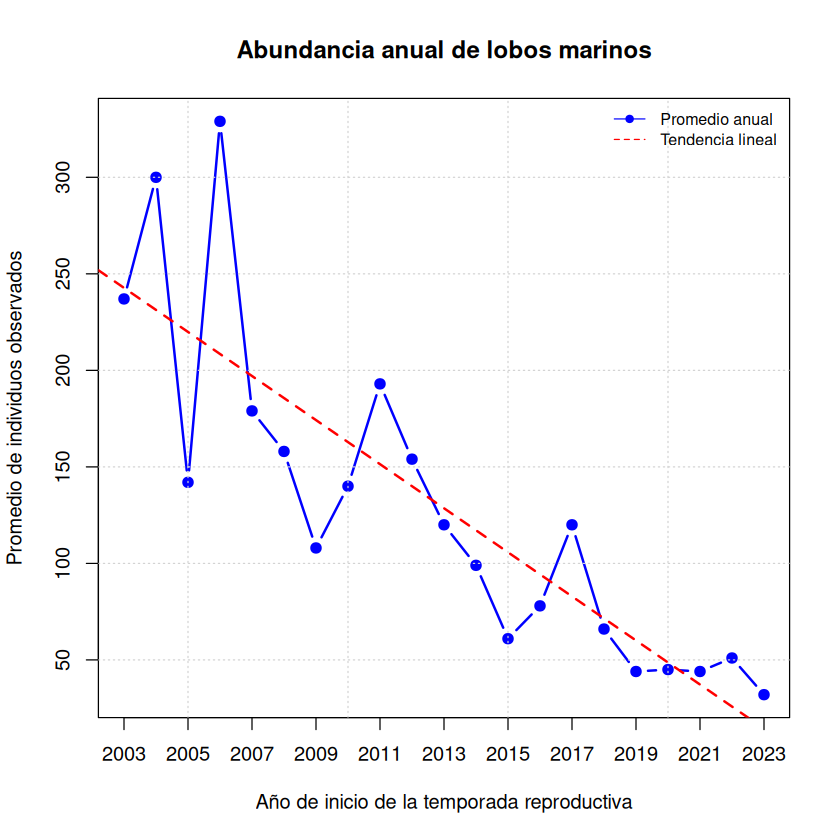

In [22]:
grafico_tendencia(
  anuales,
  "Total_avg",
  "Abundancia anual de lobos marinos",
  "blue"
)

Cambio lineal estimado: -3.09 individuos por año


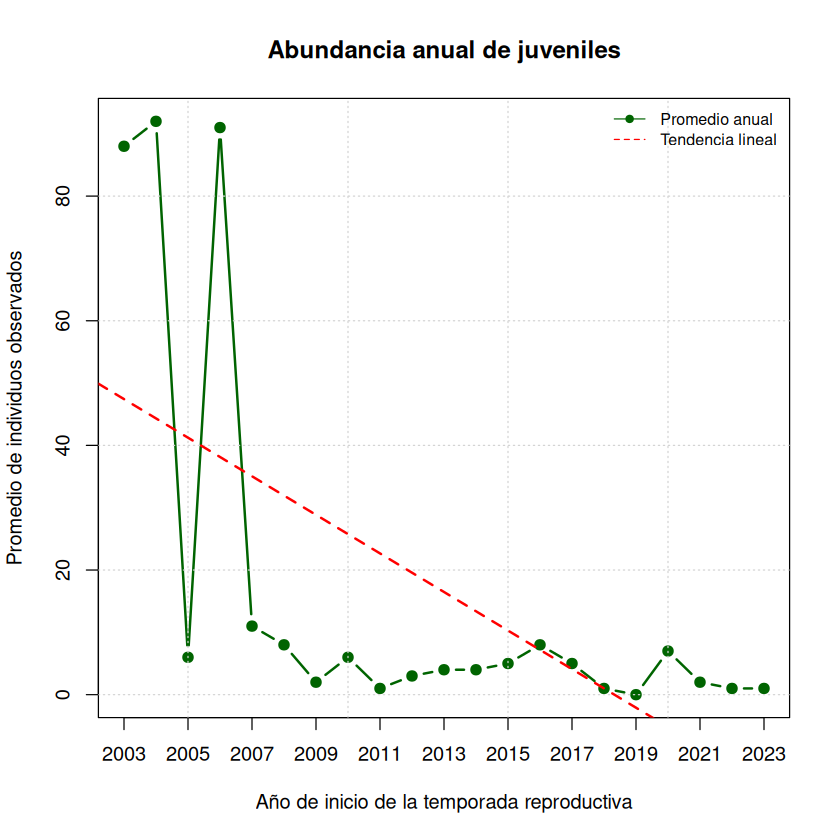

In [23]:
grafico_tendencia(
  anuales,
  "Juveniles_avg",
  "Abundancia anual de juveniles",
  "darkgreen"
)

# Actividad 2. Análisis gráfico de la abundancia de lobos marinos de Galápagos mediante R


## Resultados y análisis

Para esta actividad se trabajó con los datos de censos del lobo marino de Galápagos (*Zalophus wollebaeki*) correspondientes al periodo 2003–2023, utilizando R para calcular promedios y elaborar gráficos.

Primero se creó la función `Media()`, que permitió calcular los promedios de abundancia total, juveniles y crías. Los valores obtenidos fueron 134,76, 15,24 y 43,08 individuos, respectivamente.

Posteriormente, mediante la función `grafico_censo()`, se elaboraron dos gráficos para observar los cambios en la abundancia total y de juveniles durante los periodos reproductivos. En ambos casos se identificaron fluctuaciones, con registros más elevados en los primeros años y valores menores hacia el final del periodo de estudio.

También se creó la función `grafico_tendencia()`, que permitió representar los promedios por temporada reproductiva completa e incorporar líneas de tendencia mediante `lm()`.

La pendiente estimada para la abundancia total fue de −11,42 individuos por año, mientras que para los juveniles fue de −3,09 individuos por año. Ambas pendientes fueron negativas, lo que muestra una disminución general de los promedios observados durante el periodo analizado.

Sin embargo, estos resultados corresponden a un análisis exploratorio. Las líneas de tendencia permiten observar la dirección de los cambios, pero no son suficientes para determinar sus causas ni establecer conclusiones definitivas sobre la dinámica poblacional de la especie.

### Fuente

Childs, A. K., Stainfield, C., Stoehr, S., Twiss, S. D. y Krüger, O. (2026). *Pupping and yearling survival in Galápagos Sea Lions: impact of maternal investment, environmental fluctuations and population decline*. Dryad.

https://doi.org/10.5061/dryad.zs7h44jr0